# **1. Perkenalan Dataset**

### 1.1 Judul dan Abstrak

**Prediksi Kelas Kompleksitas Waktu Kode Sumber Berbasis Fitur Struktural dan Pembelajaran Mesin**

*Abstrak.* Kompleksitas waktu asimtotik merupakan indikator utama efisiensi suatu algoritma, tetapi penentuannya pada basis kode yang besar umumnya masih bergantung pada tinjauan manual. Penelitian ini membangun *pipeline* eksperimen untuk memprediksi kelas kompleksitas waktu terburuk (*worst-case*) dari sebuah potongan kode sumber tanpa mengeksekusinya. Kode sumber diurai menjadi *Abstract Syntax Tree* (AST), kemudian diekstraksi menjadi vektor fitur struktural, antara lain jumlah perulangan, kedalaman perulangan bersarang, keberadaan rekursi, jumlah percabangan, dan kedalaman AST. Vektor fitur tersebut selanjutnya dipakai sebagai masukan bagi model klasifikasi tabular. Notebook ini mendokumentasikan tahap awal eksperimen, yaitu pemuatan data, analisis data eksploratif (EDA), dan pra-pemrosesan, yang menghasilkan dataset tabular siap latih.

### 1.2 Latar Belakang dan Rumusan Masalah

Regresi performa, misalnya sebuah *endpoint* yang semula berkompleksitas linear berubah menjadi kuadratik setelah suatu perubahan kode, sering baru terdeteksi setelah sistem berjalan di lingkungan produksi. Analisis statis berbasis pembelajaran mesin berpotensi menjadi *performance linter* yang memberi peringatan dini pada tahap *Continuous Integration* (CI).

Rumusan masalah yang dikaji adalah sebagai berikut.

1. Sejauh mana fitur struktural hasil ekstraksi AST dapat membedakan kelas kompleksitas waktu suatu kode sumber?
2. Langkah pra-pemrosesan apa yang diperlukan agar data kode sumber mentah menjadi dataset tabular yang bersih, konsisten, dan bebas kebocoran data (*data leakage*)?

Notebook ini berfokus pada pertanyaan kedua, sedangkan pertanyaan pertama akan dijawab pada tahap pemodelan.

### 1.3 Sumber dan Karakteristik Dataset

Dataset yang digunakan adalah **CodeComplex**, yaitu kumpulan solusi pemrograman kompetitif berbahasa **Java** dan **Python** yang masing-masing berkas telah diberi label kelas kompleksitas waktu. Rincian dataset dirangkum pada tabel berikut.

| Atribut | Keterangan |
|---|---|
| Sumber | Repositori publik CodeComplex (https://github.com/sybaik1/CodeComplex); solusi kontes Codeforces |
| Bahasa pemrograman | Java dan Python |
| Unit pengamatan | Satu berkas kode sumber (satu solusi) |
| Variabel target | Kelas kompleksitas waktu terburuk, terdiri atas 7 kelas |
| Tipe data awal | Teks tidak terstruktur (kode sumber) |
| Tipe data akhir | Tabular, hasil ekstraksi fitur struktural |

Tujuh kelas target dalam urutan kompleksitas menaik adalah O(1), O(log n), O(n), O(n log n), O(n^2), O(n^3), dan NP-hard/eksponensial.

*Catatan reproduktibilitas.* Berkas mentah disimpan pada direktori `codecomplex_raw/` di akar repositori. Seluruh keluaran pra-pemrosesan disimpan pada `preprocessing/codecomplex_preprocessing/`. Seluruh proses acak menggunakan *seed* tetap.

### 1.4 Kerangka Eksperimen

Alur kerja yang dilaksanakan pada notebook ini adalah sebagai berikut.

`Data mentah` → `Pemuatan dan standardisasi` → `EDA` → `Ekstraksi fitur AST` → `Pembersihan data` → `Pembagian latih/uji` → `Penanganan outlier` → `Standardisasi fitur` → `Dataset siap latih`

Setiap langkah pra-pemrosesan pada bagian 5 akan dikonversi menjadi fungsi pada berkas `automate_<Nama>.py` dengan urutan yang identik.

# **2. Import Library**

Pustaka yang digunakan dikelompokkan menjadi tiga kategori: (i) pengolahan data dan visualisasi, (ii) pra-pemrosesan dan evaluasi statistik, serta (iii) *parsing* kode sumber menggunakan **tree-sitter**. Tree-sitter dipilih karena menyediakan tata bahasa (*grammar*) Java dan Python dengan antarmuka yang seragam, sehingga ekstraksi fitur dapat dilakukan dengan logika yang sama untuk kedua bahasa dan kelak dapat direplikasi pada implementasi C++.

In [1]:
# Instalasi dependensi (abaikan apabila lingkungan sudah memilikinya)
%pip install -q tree-sitter tree-sitter-python tree-sitter-java pandas numpy matplotlib seaborn scikit-learn scipy joblib


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# (i) Pengolahan data dan visualisasi
import json
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# (ii) Pra-pemrosesan dan statistik
import joblib
from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

# (iii) Parsing kode sumber (Abstract Syntax Tree)
from tree_sitter import Language, Parser
import tree_sitter_python as tspython
import tree_sitter_java as tsjava

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

SEED = 42
print("Seluruh pustaka berhasil dimuat.")

Matplotlib is building the font cache; this may take a moment.


Seluruh pustaka berhasil dimuat.


# **3. Memuat Dataset**

Berkas mentah (`java_data.jsonl` dan `python_data.jsonl`) telah disimpan pada direktori `codecomplex_raw/` di akar repositori, sehingga notebook ini memuatnya langsung dari sana tanpa mengunduh ulang. Fungsi pemuat dirancang agar toleran terhadap variasi skema berkas (`.jsonl`, `.json`, atau `.csv`) dengan mendeteksi kolom kode sumber, kolom label, dan kolom bahasa secara otomatis. Apabila kolom bahasa tidak tersedia, bahasa diinferensi dari nama berkas atau dari isi kode. Label asli dinormalisasi ke tujuh kelas baku.

**Catatan.** Setelah menjalankan sel pemuatan, periksa keluaran `value_counts()` label asli dan pastikan tidak ada label yang tidak terpetakan. Apabila skema berkas Anda berbeda, sesuaikan daftar `CODE_COLS`, `LABEL_COLS`, dan `LANG_COLS`.

In [3]:
# Konfigurasi jalur
# Keluaran disimpan di akar proyek sebagai codecomplex_preprocessing/ agar
# langsung bisa dibaca oleh modelling_tuning.py.
# Struktur repositori:
#   codecomplex_raw/             <- data mentah
#   codecomplex_preprocessing/   <- keluaran bersama untuk preprocessing/modeling
#   preprocessing/               <- skrip dan notebook
if Path("../codecomplex_raw").exists():            # notebook dijalankan dari folder preprocessing/
    RAW_DIR = Path("../codecomplex_raw")
    OUT_DIR = Path("../codecomplex_preprocessing")
elif Path("codecomplex_raw").exists():             # dijalankan dari akar proyek
    RAW_DIR = Path("codecomplex_raw")
    OUT_DIR = Path("codecomplex_preprocessing")
else:
    raise FileNotFoundError(
        "Folder codecomplex_raw/ tidak ditemukan. Jalankan notebook dari folder preprocessing/ "
        "atau akar proyek, dan pastikan codecomplex_raw/ tersedia."
    )
print(f"Data mentah : {RAW_DIR.resolve()}")
print(f"Keluaran    : {OUT_DIR.resolve()}")

# Kandidat nama kolom pada berkas mentah
CODE_COLS = ["src", "code", "source", "source_code", "content"]
LABEL_COLS = ["complexity", "label", "time_complexity", "target"]
LANG_COLS = ["language", "lang"]
PROBLEM_COLS = ["problem", "problem_id"]

# Urutan baku kelas kompleksitas (menaik)
CLASS_ORDER = ["O(1)", "O(log n)", "O(n)", "O(n log n)", "O(n^2)", "O(n^3)", "NP-hard/eksponensial"]

LABEL_MAP = {
    "constant": "O(1)", "o(1)": "O(1)", "1": "O(1)",
    "logn": "O(log n)", "log": "O(log n)", "o(logn)": "O(log n)",
    "linear": "O(n)", "o(n)": "O(n)", "n": "O(n)",
    "nlogn": "O(n log n)", "o(nlogn)": "O(n log n)",
    "quadratic": "O(n^2)", "o(n^2)": "O(n^2)", "o(n2)": "O(n^2)", "n2": "O(n^2)", "nsquare": "O(n^2)",
    "cubic": "O(n^3)", "o(n^3)": "O(n^3)", "o(n3)": "O(n^3)", "n3": "O(n^3)", "ncube": "O(n^3)",
    "np": "NP-hard/eksponensial", "nphard": "NP-hard/eksponensial",
    "exponential": "NP-hard/eksponensial", "o(2^n)": "NP-hard/eksponensial", "2^n": "NP-hard/eksponensial",
}


def normalize_label(value):
    key = str(value).strip().lower().replace(" ", "").replace("_", "").replace("-", "")
    return LABEL_MAP.get(key, None)


def normalize_code(code):
    """Normalisasi spasi agar duplikat yang hanya berbeda format dapat terdeteksi."""
    return re.sub(r"\s+", " ", str(code)).strip()


def _first_present(columns, candidates):
    for c in candidates:
        if c in columns:
            return c
    return None


def infer_language(code, hint=""):
    h = str(hint).lower()
    if "java" in h and "javascript" not in h:
        return "java"
    if "py" in h:
        return "python"
    return "java" if re.search(r"import java\.|public\s+(static\s+)?(class|void|int)|System\.out", str(code)) else "python"


def read_any(path):
    suffix = path.suffix.lower()
    if suffix == ".jsonl":
        return pd.read_json(path, lines=True)
    if suffix == ".json":
        try:
            return pd.read_json(path)
        except ValueError:
            with open(path, encoding="utf-8") as f:
                return pd.DataFrame(json.load(f))
    if suffix == ".csv":
        return pd.read_csv(path)
    return None


def load_raw(raw_dir):
    if not raw_dir.exists():
        raise FileNotFoundError(f"Direktori data mentah tidak ditemukan: {raw_dir.resolve()}")
    frames = []
    for path in sorted(raw_dir.rglob("*")):
        if not path.is_file():
            continue
        part = read_any(path)
        if part is None:
            continue
        part["source_file"] = str(path.relative_to(raw_dir))
        frames.append(part)
    if not frames:
        raise ValueError("Tidak ada berkas .jsonl/.json/.csv pada direktori data mentah.")
    return pd.concat(frames, ignore_index=True)


def standardize(df_raw):
    cols = list(df_raw.columns)
    code_col = _first_present(cols, CODE_COLS)
    label_col = _first_present(cols, LABEL_COLS)
    lang_col = _first_present(cols, LANG_COLS)
    if code_col is None or label_col is None:
        raise KeyError(f"Kolom kode/label tidak ditemukan. Kolom tersedia: {cols}")

    problem_col = _first_present(cols, PROBLEM_COLS)

    out = pd.DataFrame({"code": df_raw[code_col], "label_raw": df_raw[label_col]})
    if problem_col is not None:
        out["problem"] = df_raw[problem_col].astype(str)
    else:
        print("PERINGATAN: kolom 'problem' tidak ditemukan; setiap sampel diperlakukan sebagai kelompok tersendiri.")
        out["problem"] = [f"row_{i}" for i in range(len(out))]
    out["label"] = out["label_raw"].map(normalize_label)

    if lang_col is not None:
        out["language"] = df_raw[lang_col].astype(str).str.lower().map(lambda v: "java" if "java" in v else "python")
    else:
        out["language"] = [infer_language(c, h) for c, h in zip(df_raw[code_col], df_raw["source_file"])]

    unmapped = out.loc[out["label"].isna() & out["label_raw"].notna(), "label_raw"].unique()
    if len(unmapped) > 0:
        raise ValueError(f"Label berikut belum terpetakan pada LABEL_MAP: {list(unmapped)}")
    return out[["code", "language", "label", "label_raw", "problem"]].reset_index(drop=True)


df_raw = load_raw(RAW_DIR)
print(f"Data mentah berhasil dimuat dari: {RAW_DIR.resolve()}")
print(f"Dimensi data mentah: {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")

Data mentah : /Users/bryannoel/Desktop/Folders/coding/Eksperimen_SML_BryanNoel/codecomplex_raw
Keluaran    : /Users/bryannoel/Desktop/Folders/coding/Eksperimen_SML_BryanNoel/preprocessing/codecomplex_preprocessing
Data mentah berhasil dimuat dari: /Users/bryannoel/Desktop/Folders/coding/Eksperimen_SML_BryanNoel/codecomplex_raw
Dimensi data mentah: 9,800 baris x 6 kolom


Tahap berikut menampilkan lima baris pertama, ringkasan tipe data, serta label asli untuk memverifikasi bahwa data telah termuat dengan benar.

In [4]:
display(df_raw.head())
print()
df_raw.info()

,src,complexity,problem,from,tags,source_file
0,import java.io.*;\n\n//@author Maurice Saldiva...,constant,0005_D,CODEFORCES,"implementation,math",java_data.jsonl
1,import java.util.*;\nimport static java.lang.M...,constant,0005_D,CODEFORCES,"implementation,math",java_data.jsonl
2,import java.util.*;\n\npublic class Rules {\n ...,constant,0005_D,CODEFORCES,"implementation,math",java_data.jsonl
3,import java.io.*;\nimport java.text.*;\nimport...,constant,0005_D,CODEFORCES,"implementation,math",java_data.jsonl
4,import java.io.BufferedReader;\nimport java.io...,constant,0005_D,CODEFORCES,"implementation,math",java_data.jsonl



<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   src          9800 non-null   str  
 1   complexity   9800 non-null   str  
 2   problem      9800 non-null   str  
 3   from         9800 non-null   str  
 4   tags         9800 non-null   str  
 5   source_file  9800 non-null   str  
dtypes: str(6)
memory usage: 459.5 KB


In [5]:
# Verifikasi label asli sebelum dinormalisasi
label_col_detected = _first_present(list(df_raw.columns), LABEL_COLS)
print(f"Kolom label terdeteksi: '{label_col_detected}'")
print(df_raw[label_col_detected].value_counts(dropna=False))

Kolom label terdeteksi: 'complexity'
complexity
linear       1632
constant     1541
nlogn        1496
quadratic    1422
logn         1369
cubic        1207
np           1133
Name: count, dtype: int64


Selanjutnya, data distandardisasi menjadi kolom baku: `code` (teks kode sumber), `language` (java/python), `label` (tujuh kelas kompleksitas), dan `problem` (identitas soal, dipakai untuk pembagian data pada bagian 5.4).

In [6]:
df = standardize(df_raw)
print(f"Dimensi dataset terstandardisasi: {df.shape}")
display(df.head())

print("\nContoh potongan kode (baris pertama):")
print(f"Bahasa: {df.loc[0, 'language']} | Label: {df.loc[0, 'label']}")
print("-" * 60)
print(str(df.loc[0, "code"])[:600])

Dimensi dataset terstandardisasi: (9800, 5)


,code,language,label,label_raw,problem
0,import java.io.*;\n\n//@author Maurice Saldiva...,java,O(1),constant,0005_D
1,import java.util.*;\nimport static java.lang.M...,java,O(1),constant,0005_D
2,import java.util.*;\n\npublic class Rules {\n ...,java,O(1),constant,0005_D
3,import java.io.*;\nimport java.text.*;\nimport...,java,O(1),constant,0005_D
4,import java.io.BufferedReader;\nimport java.io...,java,O(1),constant,0005_D



Contoh potongan kode (baris pertama):
Bahasa: java | Label: O(1)
------------------------------------------------------------
import java.io.*;

//@author Maurice Saldivar
public class Main {

    public static void main(String[] args) throws Exception{

        BufferedReader br = new BufferedReader(new InputStreamReader(System.in));
        PrintWriter pr = new PrintWriter(System.out);
        double totalTime = 0;
        int A = 0, V = 0, L = 0, D = 0, W = 0;
        String tokens[];
        tokens = br.readLine().split("\\s+");
        A = Integer.parseInt(tokens[0]);
        V = Integer.parseInt(tokens[1]);
        tokens = br.readLine().split("\\s+");
        L = Integer.parseInt(tokens[0]);
        D = Intege


# **4. Exploratory Data Analysis (EDA)**

Analisis eksploratif dilakukan untuk memahami kualitas data, distribusi kelas, serta hubungan antara fitur struktural dan kelas kompleksitas. Hasil EDA menjadi dasar pemilihan langkah pra-pemrosesan pada bagian 5.

Catatan interpretasi pada setiap subbagian ditulis sebagai **hipotesis analitis**. Hipotesis tersebut perlu dikonfirmasi terhadap keluaran aktual sel di atasnya.

### 4.1 Kualitas Data: Nilai Kosong, Duplikasi, dan Konflik Label

Kualitas data diperiksa melalui tiga indikator: (i) jumlah nilai kosong, (ii) jumlah kode duplikat setelah normalisasi spasi, dan (iii) jumlah kode identik yang memiliki label berbeda (konflik label). Konflik label berbahaya karena memberikan sinyal pelatihan yang kontradiktif terhadap model.

In [7]:
print("Jumlah nilai kosong per kolom:")
print(df[["code", "language", "label"]].isna().sum().to_string())

code_filled = df["code"].fillna("")
empty_code = int((code_filled.str.strip() == "").sum())
norm = code_filled.map(normalize_code)

dup_count = int(norm.duplicated().sum())
grp = df.assign(_norm=norm).groupby("_norm")["label"].nunique()
conflict_count = int((grp > 1).sum())

print(f"\nKode kosong                       : {empty_code:,}")
print(f"Kode duplikat (setelah normalisasi): {dup_count:,} ({dup_count / len(df):.2%})")
print(f"Kelompok kode dengan label konflik : {conflict_count:,}")

Jumlah nilai kosong per kolom:
code        0
language    0
label       0

Kode kosong                       : 0
Kode duplikat (setelah normalisasi): 355 (3.62%)
Kelompok kode dengan label konflik : 61


*Hipotesis analitis.* Dataset hasil kurasi lazimnya memiliki nilai kosong yang sangat sedikit. Namun, solusi pemrograman kompetitif cenderung memuat templat yang berulang sehingga duplikasi dan kemiripan tinggi antarberkas perlu diwaspadai. Duplikasi yang tidak ditangani dapat menyebabkan data yang sama muncul pada himpunan latih dan uji, sehingga performa model menjadi terlalu optimistis.

### 4.2 Distribusi Kelas Target

Distribusi kelas diperiksa untuk mengidentifikasi ketidakseimbangan kelas (*class imbalance*), yang memengaruhi pemilihan strategi pembagian data dan metrik evaluasi.

,jumlah,persentase
label,,
O(1),1541,15.72
O(log n),1369,13.97
O(n),1632,16.65
O(n log n),1496,15.27
O(n^2),1422,14.51
O(n^3),1207,12.32
NP-hard/eksponensial,1133,11.56


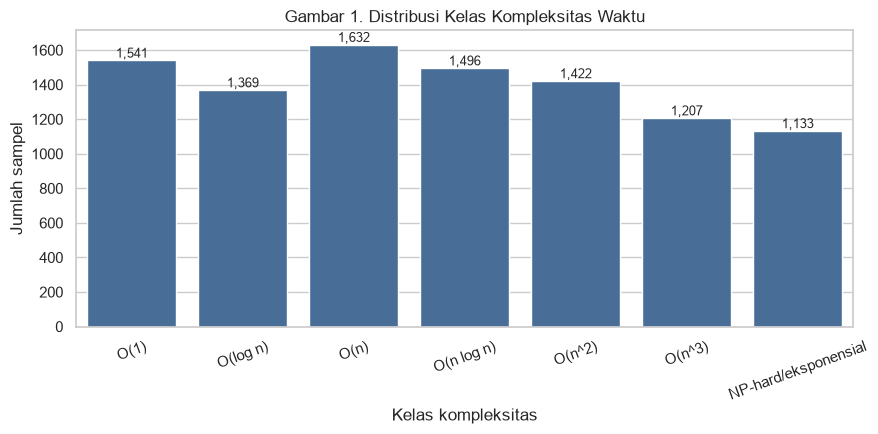

Rasio ketidakseimbangan (kelas terbesar : terkecil) = 1.44 : 1


In [8]:
class_counts = df["label"].value_counts().reindex(CLASS_ORDER).fillna(0).astype(int)
display(class_counts.to_frame("jumlah").assign(persentase=lambda d: (d["jumlah"] / d["jumlah"].sum() * 100).round(2)))

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=class_counts.index, y=class_counts.values, color="#3b6ea5", ax=ax)
for i, v in enumerate(class_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Gambar 1. Distribusi Kelas Kompleksitas Waktu")
ax.set_xlabel("Kelas kompleksitas")
ax.set_ylabel("Jumlah sampel")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

nonzero = class_counts[class_counts > 0]
print(f"Rasio ketidakseimbangan (kelas terbesar : terkecil) = {nonzero.max() / nonzero.min():.2f} : 1")

*Hipotesis analitis.* Apabila rasio ketidakseimbangan jauh di atas 1, pembagian data wajib menggunakan stratifikasi dan evaluasi model sebaiknya tidak hanya bertumpu pada akurasi, melainkan juga pada *macro-F1* serta *confusion matrix*.

### 4.3 Distribusi Bahasa Pemrograman

,jumlah
language,
java,4900
python,4900


language,java,python
label,,
O(1),750,791
O(log n),700,669
O(n),779,853
O(n log n),700,796
O(n^2),765,657
O(n^3),601,606
NP-hard/eksponensial,605,528


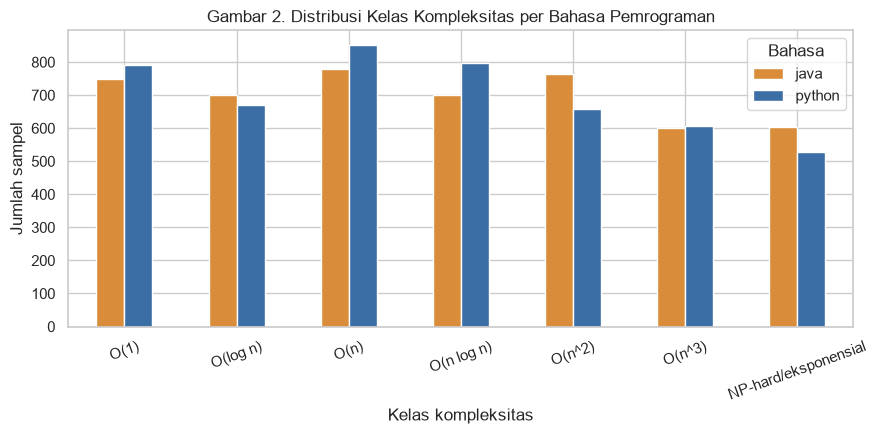

In [9]:
lang_counts = df["language"].value_counts()
display(lang_counts.to_frame("jumlah"))

ct = pd.crosstab(df["label"], df["language"]).reindex(CLASS_ORDER).fillna(0).astype(int)
display(ct)

ct.plot(kind="bar", figsize=(9, 4.5), color=["#d98c3a", "#3b6ea5"])
plt.title("Gambar 2. Distribusi Kelas Kompleksitas per Bahasa Pemrograman")
plt.xlabel("Kelas kompleksitas")
plt.ylabel("Jumlah sampel")
plt.xticks(rotation=20)
plt.legend(title="Bahasa")
plt.tight_layout()
plt.show()

*Hipotesis analitis.* Apabila proporsi kelas berbeda signifikan antarbahasa, maka bahasa pemrograman berpotensi menjadi fitur yang informatif sekaligus sumber bias. Oleh karena itu, bahasa akan dikodekan sebagai fitur biner dan dipertahankan dalam dataset.

#### 4.3.1 Distribusi Solusi per Soal

Setiap sampel pada CodeComplex merupakan solusi atas suatu soal Codeforces (kolom `problem`), dan satu soal umumnya memiliki banyak solusi. Apabila solusi dari soal yang sama tersebar ke data latih dan data uji, model berpeluang mengenali pola khas soal tersebut alih-alih mempelajari hubungan antara struktur kode dan kompleksitas, sehingga skor uji menjadi terlalu optimistis. Oleh karena itu, jumlah soal unik dan sebaran solusi per soal diperiksa sebagai dasar pemilihan skema pembagian data.

In [10]:
per_problem = df.groupby("problem").size()
print(f"Jumlah soal unik          : {per_problem.shape[0]:,}")
print(f"Rata-rata solusi per soal : {per_problem.mean():.1f}")
print(f"Median solusi per soal    : {per_problem.median():.0f}")
print(f"Maksimum solusi per soal  : {per_problem.max():,}")

print("\nSoal unik per bahasa:")
print(df.groupby("language")["problem"].nunique().to_string())

shared = set(df.loc[df["language"] == "java", "problem"]) & set(df.loc[df["language"] == "python", "problem"])
print(f"\nSoal yang muncul pada kedua bahasa      : {len(shared):,}")

multi_label = int((df.groupby("problem")["label"].nunique() > 1).sum())
print(f"Soal dengan lebih dari satu kelas label : {multi_label:,}")

Jumlah soal unik          : 300
Rata-rata solusi per soal : 32.7
Median solusi per soal    : 21
Maksimum solusi per soal  : 263

Soal unik per bahasa:
language
java      258
python    277

Soal yang muncul pada kedua bahasa      : 235
Soal dengan lebih dari satu kelas label : 53


Mengingat jumlah soal unik jauh lebih sedikit daripada jumlah sampel, pembagian data pada subbagian 5.4 dilakukan per soal (*grouped split*) dengan stratifikasi kelas, bukan per sampel secara acak.

### 4.4 Ekstraksi Fitur Struktural dari AST

Kode sumber merupakan data tidak terstruktur, sehingga perlu dikonversi menjadi vektor fitur numerik. Pada tahap ini didefinisikan fungsi `extract_features` yang melakukan satu kali penelusuran AST untuk menghitung fitur-fitur berikut.

| Kelompok | Fitur |
|---|---|
| Ukuran | `loc`, `n_chars`, `ast_nodes`, `ast_depth` |
| Perulangan | `loop_count`, `for_count`, `while_count`, `max_loop_depth`, `comprehension_count` |
| Percabangan | `branch_count`, `max_nesting_depth` |
| Fungsi dan rekursi | `func_count`, `call_count`, `has_recursion`, `max_recursive_calls` |
| Pola algoritmik (leksikal) | `has_sort`, `has_halving`, `has_doubling`, `has_binary_search`, `has_heap`, `has_hash_container`, `has_memo` |
| Meta | `is_java`, `parse_error` |

Fitur pola algoritmik dirancang untuk membedakan kelas yang tidak dapat dibedakan hanya dari kedalaman perulangan, misalnya O(log n) (pembagian dua berulang) dan O(n log n) (pemanggilan pengurutan). Fitur `parse_error` hanya digunakan untuk audit kualitas ekstraksi dan tidak dimasukkan sebagai fitur model.

In [11]:
PARSERS = {
    "python": Parser(Language(tspython.language())),
    "java": Parser(Language(tsjava.language())),
}

NODE_CFG = {
    "python": {
        "for": {"for_statement"},
        "while": {"while_statement"},
        "comp": {"list_comprehension", "set_comprehension", "dictionary_comprehension", "generator_expression"},
        "branch": {"if_statement", "elif_clause", "conditional_expression", "match_statement"},
        "func": {"function_definition"},
        "call": {"call"},
    },
    "java": {
        "for": {"for_statement", "enhanced_for_statement"},
        "while": {"while_statement", "do_statement"},
        "comp": set(),
        "branch": {"if_statement", "switch_expression", "switch_statement", "ternary_expression"},
        "func": {"method_declaration", "constructor_declaration"},
        "call": {"method_invocation"},
    },
}

RE_SORT = re.compile(r"\bsorted?\s*\(|\.sort\s*\(|\bArrays\.sort\b|\bCollections\.sort\b")
RE_HALVING = re.compile(r"/=?\s*2\b|>>=?\s*1\b")
RE_DOUBLING = re.compile(r"\*=\s*2\b|<<=?\s*1\b|\*\s*2\b")
RE_BSEARCH = re.compile(r"bisect|binarySearch|\bmid\b")
RE_HEAP = re.compile(r"heapq|heappush|heappop|PriorityQueue")
RE_HASH = re.compile(r"\bdict\s*\(|\bset\s*\(|defaultdict|Counter\s*\(|HashMap|HashSet|LinkedHashMap")
RE_MEMO = re.compile(r"lru_cache|\bmemo\b|\bcache\b|\bdp\b")


def _text(node):
    return node.text.decode("utf-8", errors="ignore") if node is not None else ""


def _callee_name(call_node, language):
    if language == "python":
        fn = call_node.child_by_field_name("function")
        if fn is None:
            return ""
        if fn.type == "identifier":
            return _text(fn)
        if fn.type == "attribute":
            return _text(fn.child_by_field_name("attribute"))
        return ""
    return _text(call_node.child_by_field_name("name"))


def _iter_nodes(root):
    stack = [root]
    while stack:
        node = stack.pop()
        yield node
        stack.extend(node.children)


def extract_features(code, language):
    """Ekstraksi vektor fitur struktural dari satu potongan kode (satu kali penelusuran AST)."""
    code = "" if code is None else str(code)
    cfg = NODE_CFG[language]
    tree = PARSERS[language].parse(code.encode("utf-8", errors="ignore"))
    root = tree.root_node

    ast_nodes = ast_depth = 0
    loop_count = for_count = while_count = comp_count = 0
    branch_count = call_count = 0
    max_loop_depth = max_nest = 0
    func_nodes = []

    stack = [(root, 1, 0, 0)]  # (node, kedalaman AST, kedalaman loop, kedalaman nesting)
    while stack:
        node, d, ld, nd = stack.pop()
        ast_nodes += 1
        ast_depth = max(ast_depth, d)
        t = node.type
        new_ld, new_nd = ld, nd

        if t in cfg["for"]:
            for_count += 1; loop_count += 1; new_ld += 1; new_nd += 1
        elif t in cfg["while"]:
            while_count += 1; loop_count += 1; new_ld += 1; new_nd += 1
        elif t in cfg["comp"]:
            k = sum(1 for c in node.children if c.type == "for_in_clause")
            comp_count += 1; loop_count += k; for_count += k; new_ld += k; new_nd += k
        elif t in cfg["branch"]:
            branch_count += 1
            is_else_if = (t == "if_statement" and node.parent is not None and node.parent.type == "if_statement")
            if t != "elif_clause" and not is_else_if:
                new_nd += 1
        elif t in cfg["func"]:
            func_nodes.append(node)

        if t in cfg["call"]:
            call_count += 1

        max_loop_depth = max(max_loop_depth, new_ld)
        max_nest = max(max_nest, new_nd)
        for c in node.children:
            stack.append((c, d + 1, new_ld, new_nd))

    # Rekursi: panggilan fungsi terhadap dirinya sendiri
    max_rec_calls = 0
    for fn in func_nodes:
        name = _text(fn.child_by_field_name("name"))
        if not name:
            continue
        n_self = sum(1 for n in _iter_nodes(fn)
                     if n.type in cfg["call"] and _callee_name(n, language) == name)
        max_rec_calls = max(max_rec_calls, n_self)

    lines = [ln for ln in code.splitlines() if ln.strip()]
    return {
        "loc": len(lines),
        "n_chars": len(code),
        "ast_nodes": ast_nodes,
        "ast_depth": ast_depth,
        "loop_count": loop_count,
        "for_count": for_count,
        "while_count": while_count,
        "comprehension_count": comp_count,
        "max_loop_depth": max_loop_depth,
        "branch_count": branch_count,
        "max_nesting_depth": max_nest,
        "func_count": len(func_nodes),
        "call_count": call_count,
        "max_recursive_calls": max_rec_calls,
        "has_recursion": int(max_rec_calls > 0),
        "has_sort": int(bool(RE_SORT.search(code))),
        "has_halving": int(bool(RE_HALVING.search(code))),
        "has_doubling": int(bool(RE_DOUBLING.search(code))),
        "has_binary_search": int(bool(RE_BSEARCH.search(code))),
        "has_heap": int(bool(RE_HEAP.search(code))),
        "has_hash_container": int(bool(RE_HASH.search(code))),
        "has_memo": int(bool(RE_MEMO.search(code))),
        "is_java": int(language == "java"),
        "parse_error": int(root.has_error),
    }


COUNT_FEATURES = ["loc", "n_chars", "ast_nodes", "ast_depth", "loop_count", "for_count", "while_count",
                  "comprehension_count", "max_loop_depth", "branch_count", "max_nesting_depth",
                  "func_count", "call_count", "max_recursive_calls"]
BINARY_FEATURES = ["has_recursion", "has_sort", "has_halving", "has_doubling", "has_binary_search",
                   "has_heap", "has_hash_container", "has_memo", "is_java"]
FEATURES = COUNT_FEATURES + BINARY_FEATURES


def extract_all(frame):
    rows = []
    for code_text, lang in zip(frame["code"], frame["language"]):
        try:
            rows.append(extract_features(code_text, lang))
        except Exception:
            failed = {k: np.nan for k in COUNT_FEATURES + BINARY_FEATURES}
            failed["is_java"] = int(lang == "java")
            failed["parse_error"] = 1
            rows.append(failed)
    return pd.DataFrame(rows, index=frame.index)


df_feat = extract_all(df)
df_all = pd.concat([df, df_feat], axis=1)
df_all["label_ord"] = df_all["label"].map({c: i for i, c in enumerate(CLASS_ORDER)})
print(f"Ekstraksi selesai: {df_feat.shape[0]:,} sampel x {len(FEATURES)} fitur model.")
display(df_all[["language", "label"] + FEATURES].head())

Ekstraksi selesai: 9,800 sampel x 23 fitur model.


,language,label,loc,n_chars,ast_nodes,ast_depth,loop_count,for_count,while_count,comprehension_count,max_loop_depth,branch_count,max_nesting_depth,func_count,call_count,max_recursive_calls,has_recursion,has_sort,has_halving,has_doubling,has_binary_search,has_heap,has_hash_container,has_memo,is_java
0,java,O(1),48,2098,881,23,0,0,0,0,0,6,3,1,16,0,0,0,1,1,0,0,0,0,1
1,java,O(1),37,1238,588,17,0,0,0,0,0,3,1,4,15,0,0,0,0,0,0,0,0,0,1
2,java,O(1),80,3208,914,16,1,0,1,0,1,6,2,3,20,0,0,0,1,0,0,0,0,0,1
3,java,O(1),68,1697,838,18,0,0,0,0,0,3,2,4,18,0,0,0,1,0,0,0,0,0,1
4,java,O(1),95,2804,991,18,1,0,1,0,1,4,2,9,27,0,0,0,1,1,0,0,0,0,1


Statistik deskriptif fitur ditampilkan untuk mengamati rentang nilai, kemiringan distribusi, dan keberadaan nilai ekstrem.

In [12]:
display(df_all[COUNT_FEATURES].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2))

,count,mean,std,min,1%,25%,50%,75%,99%,max
loc,9800.0,65.90,89.17,1.0,2.0,19.0,37.0,83.00,402.00,2488.0
n_chars,9800.0,1898.03,2806.31,9.0,62.0,440.0,982.0,2430.25,11963.31,64616.0
ast_nodes,9800.0,750.92,943.63,8.0,47.0,236.0,453.0,936.00,4415.01,22448.0
ast_depth,9800.0,16.14,3.86,5.0,9.0,13.0,16.0,18.00,26.00,45.0
loop_count,9800.0,5.51,7.26,0.0,0.0,1.0,3.0,7.00,30.00,163.0
for_count,9800.0,4.17,5.68,0.0,0.0,1.0,3.0,5.00,24.00,127.0
while_count,9800.0,1.34,2.59,0.0,0.0,0.0,0.0,2.00,12.00,36.0
comprehension_count,9800.0,0.49,1.60,0.0,0.0,0.0,0.0,0.00,6.01,34.0
max_loop_depth,9800.0,1.61,1.03,0.0,0.0,1.0,1.0,2.00,4.00,9.0
branch_count,9800.0,5.22,7.61,0.0,0.0,1.0,3.0,6.00,33.00,151.0


### 4.5 Distribusi Panjang Kode per Kelas

Panjang kode (jumlah karakter dan baris tak kosong) diperiksa karena menentukan seberapa besar pengaruh nilai ekstrem terhadap fitur berskala hitungan.

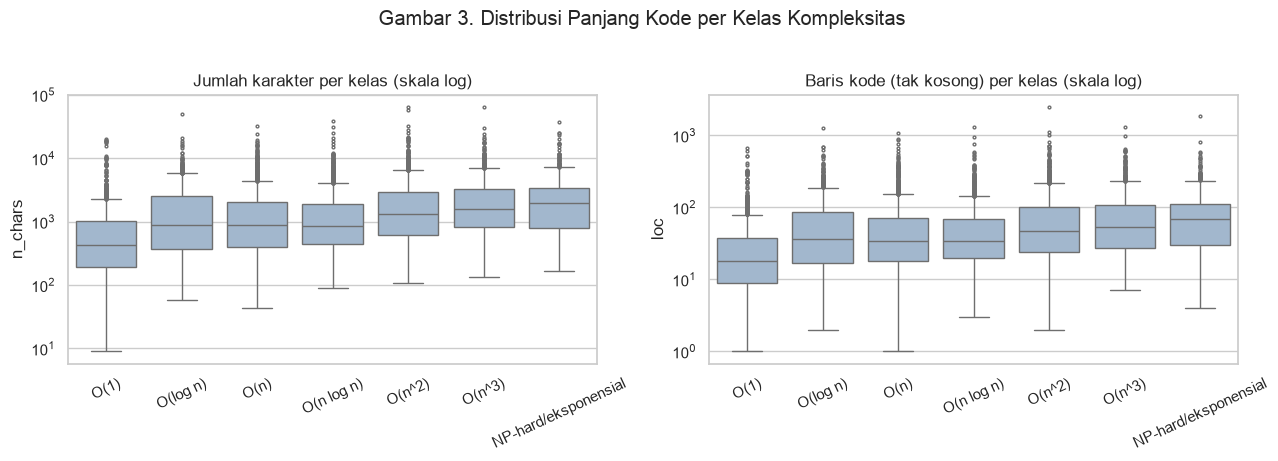

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, title in zip(axes, ["n_chars", "loc"], ["Jumlah karakter", "Baris kode (tak kosong)"]):
    sns.boxplot(data=df_all, x="label", y=col, order=CLASS_ORDER, color="#9bb7d4", fliersize=2, ax=ax)
    ax.set_yscale("log")
    ax.set_title(f"{title} per kelas (skala log)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Gambar 3. Distribusi Panjang Kode per Kelas Kompleksitas", y=1.02)
plt.tight_layout()
plt.show()

*Hipotesis analitis.* Distribusi panjang kode umumnya menceng ke kanan (*right-skewed*) dengan banyak pencilan. Kondisi ini mendasari penerapan pemangkasan nilai ekstrem (*winsorization*) pada fitur berskala hitungan sebelum standardisasi.

### 4.6 Hubungan Fitur Struktural dengan Kelas Kompleksitas

Rata-rata setiap fitur kunci per kelas divisualisasikan dalam bentuk *heatmap*. Pola yang diharapkan adalah kenaikan `max_loop_depth` seiring naiknya orde kompleksitas polinomial, `has_recursion` yang menonjol pada kelas eksponensial, serta `has_halving` dan `has_sort` yang menonjol pada kelas logaritmik.

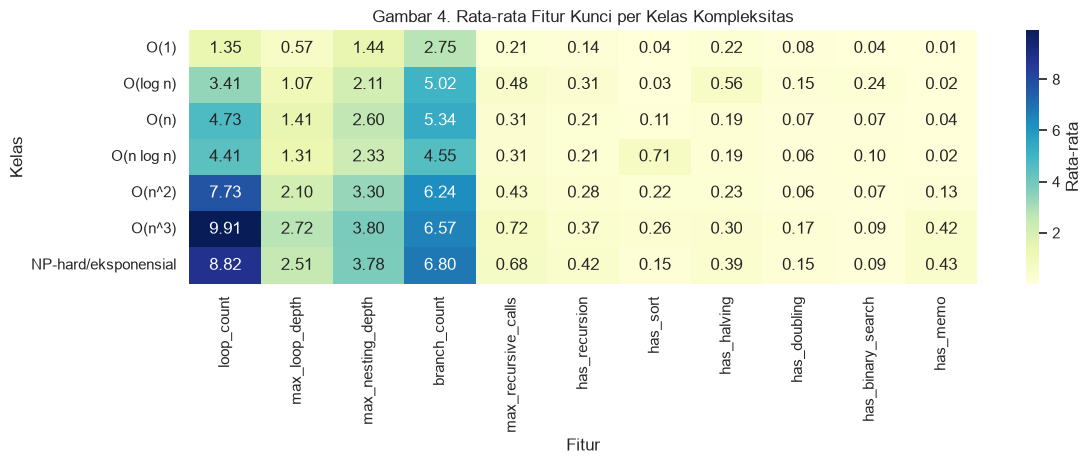

In [14]:
key_feats = ["loop_count", "max_loop_depth", "max_nesting_depth", "branch_count", "max_recursive_calls",
             "has_recursion", "has_sort", "has_halving", "has_doubling", "has_binary_search", "has_memo"]
summary = df_all.groupby("label")[key_feats].mean().reindex(CLASS_ORDER)

plt.figure(figsize=(12, 4.8))
sns.heatmap(summary, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "Rata-rata"})
plt.title("Gambar 4. Rata-rata Fitur Kunci per Kelas Kompleksitas")
plt.xlabel("Fitur")
plt.ylabel("Kelas")
plt.tight_layout()
plt.show()

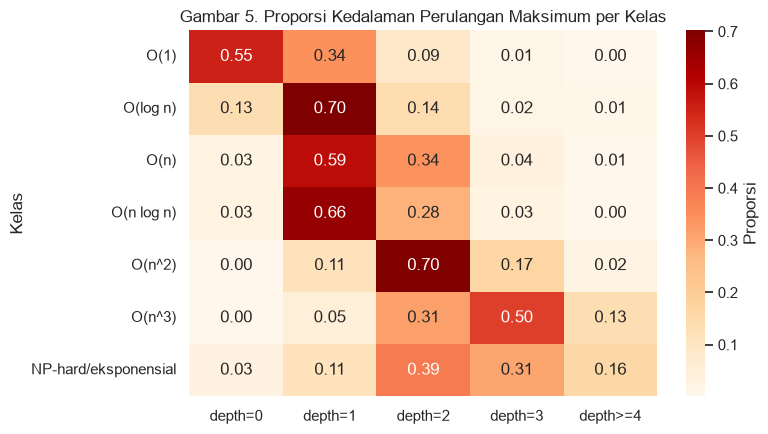

In [15]:
# Proporsi kedalaman perulangan maksimum (dipangkas pada 4) pada setiap kelas
depth = df_all["max_loop_depth"].clip(upper=4).astype("Int64")
depth_ct = pd.crosstab(df_all["label"], depth, normalize="index").reindex(CLASS_ORDER)
depth_ct.columns = [f"depth={c}" if c < 4 else "depth>=4" for c in depth_ct.columns]

plt.figure(figsize=(8, 4.5))
sns.heatmap(depth_ct, annot=True, fmt=".2f", cmap="OrRd", cbar_kws={"label": "Proporsi"})
plt.title("Gambar 5. Proporsi Kedalaman Perulangan Maksimum per Kelas")
plt.xlabel("")
plt.ylabel("Kelas")
plt.tight_layout()
plt.show()

*Hipotesis analitis.* Apabila kedalaman perulangan bergeser ke nilai yang lebih besar pada kelas O(n^2) dan O(n^3), hal ini mengonfirmasi bahwa `max_loop_depth` merupakan prediktor yang kuat. Sebaliknya, apabila kelas O(n) dan O(n log n) atau O(log n) memiliki distribusi kedalaman yang saling tumpang tindih, maka fitur pola algoritmik (pengurutan dan pembagian dua) diperlukan untuk memisahkannya, dan keterbatasan ini perlu dicermati pada tahap evaluasi model.

### 4.7 Korelasi Antarfitur

Matriks korelasi Spearman digunakan karena sebagian besar fitur berupa hitungan diskret yang tidak berdistribusi normal. Korelasi yang sangat tinggi antarfitur mengindikasikan redundansi, sedangkan korelasi terhadap urutan kelas (`label_ord`) memberi gambaran awal kekuatan prediktif tiap fitur.

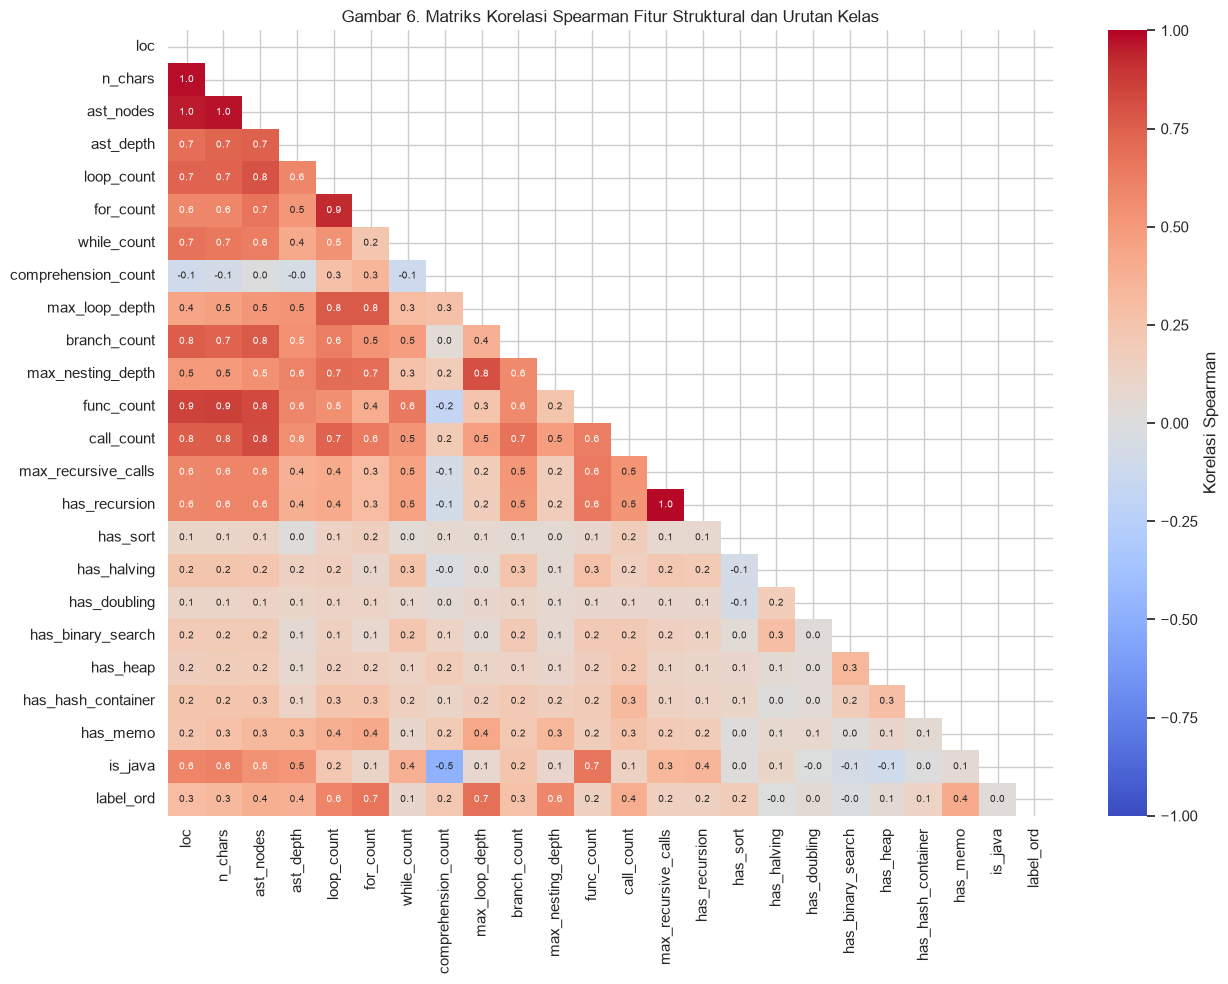

In [16]:
corr_cols = FEATURES + ["label_ord"]
corr = df_all[corr_cols].corr(method="spearman")

plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"label": "Korelasi Spearman"})
plt.title("Gambar 6. Matriks Korelasi Spearman Fitur Struktural dan Urutan Kelas")
plt.tight_layout()
plt.show()

### 4.8 Ringkasan Temuan EDA

Sel berikut menyusun ringkasan kuantitatif secara otomatis dari data aktual, sehingga kesimpulan yang ditulis pada laporan tetap konsisten dengan hasil eksekusi.

In [17]:
rho = {}
for f in FEATURES:
    r, _ = spearmanr(df_all[f], df_all["label_ord"], nan_policy="omit")
    rho[f] = r
rho = pd.Series(rho).dropna().sort_values(key=np.abs, ascending=False)

parse_err_rate = df_all["parse_error"].mean()
nan_feat = int(df_all[FEATURES].isna().any(axis=1).sum())

print("RINGKASAN TEMUAN EDA")
print("=" * 60)
print(f"1. Jumlah sampel                      : {len(df_all):,}")
print(f"2. Rasio ketidakseimbangan kelas      : {nonzero.max() / nonzero.min():.2f} : 1")
print(f"3. Duplikat (setelah normalisasi)     : {dup_count:,} ({dup_count / len(df_all):.2%})")
print(f"4. Kelompok kode dengan label konflik : {conflict_count:,}")
print(f"5. Sampel dengan galat sintaks (AST)  : {parse_err_rate:.2%}")
print(f"6. Sampel dengan fitur gagal diekstrak: {nan_feat:,}")
print("7. Lima fitur dengan |korelasi Spearman| tertinggi terhadap urutan kelas:")
for name, val in rho.head(5).items():
    print(f"     - {name:<22} rho = {val:+.3f}")

RINGKASAN TEMUAN EDA
1. Jumlah sampel                      : 9,800
2. Rasio ketidakseimbangan kelas      : 1.44 : 1
3. Duplikat (setelah normalisasi)     : 355 (3.62%)
4. Kelompok kode dengan label konflik : 61
5. Sampel dengan galat sintaks (AST)  : 0.05%
6. Sampel dengan fitur gagal diekstrak: 0
7. Lima fitur dengan |korelasi Spearman| tertinggi terhadap urutan kelas:
     - max_loop_depth         rho = +0.684
     - for_count              rho = +0.665
     - loop_count             rho = +0.595
     - max_nesting_depth      rho = +0.585
     - has_memo               rho = +0.409


*Implikasi terhadap pra-pemrosesan.* Berdasarkan ringkasan di atas, bagian 5 menerapkan langkah-langkah berikut: (1) penghapusan data kosong, (2) penghapusan duplikat dan konflik label, (3) pengodean target dan bahasa, (4) pembagian latih/uji per soal (*grouped split*) dengan stratifikasi kelas, (5) pemangkasan pencilan berbasis persentil yang dihitung dari data latih, dan (6) standardisasi fitur hitungan yang dipelajari dari data latih saja.

# **5. Data Preprocessing**

Pra-pemrosesan dilaksanakan dengan prinsip pencegahan kebocoran data (*data leakage*): seluruh statistik yang dipelajari dari data, yaitu median, batas pemangkasan, dan parameter standardisasi, dihitung **hanya dari data latih** dan kemudian diterapkan pada data uji. Fitur diekstraksi pada bagian 4.4 dan digunakan kembali pada bagian ini karena ekstraksi bersifat deterministik per sampel dan tidak bergantung pada sampel lain.

### 5.1 Penanganan Data Kosong

Baris dengan kode kosong atau label kosong tidak dapat dipakai untuk pelatihan sehingga dihapus. Nilai kosong pada fitur numerik (akibat kegagalan ekstraksi) ditangani pada subbagian 5.5 menggunakan median data latih.

In [18]:
n_before = len(df_all)
df_clean = df_all.copy()
df_clean["code"] = df_clean["code"].fillna("")

valid_mask = df_clean["code"].str.strip().ne("") & df_clean["label"].notna()
df_clean = df_clean[valid_mask].copy()

print(f"Baris sebelum : {n_before:,}")
print(f"Baris sesudah : {len(df_clean):,}")
print(f"Baris dihapus : {n_before - len(df_clean):,}")

Baris sebelum : 9,800
Baris sesudah : 9,800
Baris dihapus : 0


### 5.2 Penghapusan Duplikat dan Konflik Label

Dua tindakan dilakukan secara berurutan. Pertama, kelompok kode yang identik setelah normalisasi spasi tetapi memiliki label berbeda dihapus seluruhnya, karena label yang benar tidak dapat ditentukan. Kedua, duplikat murni direduksi menjadi satu salinan.

In [19]:
n_before = len(df_clean)
df_clean["_norm"] = df_clean["code"].map(normalize_code)

label_nunique = df_clean.groupby("_norm")["label"].nunique()
conflict_keys = set(label_nunique[label_nunique > 1].index)
df_clean = df_clean[~df_clean["_norm"].isin(conflict_keys)]
n_after_conflict = len(df_clean)

df_clean = df_clean.drop_duplicates(subset="_norm", keep="first").drop(columns="_norm")

print(f"Baris awal                         : {n_before:,}")
print(f"Dihapus (konflik label)            : {n_before - n_after_conflict:,}")
print(f"Dihapus (duplikat murni)           : {n_after_conflict - len(df_clean):,}")
print(f"Baris akhir                        : {len(df_clean):,}")

Baris awal                         : 9,800
Dihapus (konflik label)            : 133
Dihapus (duplikat murni)           : 283
Baris akhir                        : 9,384


### 5.3 Pengodean Data Kategorikal

Variabel target dikodekan menjadi bilangan bulat mengikuti **urutan kompleksitas** (bukan urutan alfabet), sehingga indeks kelas mempertahankan makna ordinalnya. Bahasa pemrograman dikodekan sebagai fitur biner `is_java` (1 untuk Java, 0 untuk Python); fitur ini telah dibentuk pada tahap ekstraksi.

In [20]:
label2id = {c: i for i, c in enumerate(CLASS_ORDER)}
id2label = {i: c for c, i in label2id.items()}

df_clean["target"] = df_clean["label"].map(label2id).astype(int)

missing_classes = [c for c in CLASS_ORDER if c not in set(df_clean["label"])]
if missing_classes:
    print(f"PERINGATAN: kelas berikut tidak muncul pada data: {missing_classes}")

display(df_clean[["language", "is_java", "label", "target"]].drop_duplicates().sort_values("target").head(14))

,language,is_java,label,target
0,java,1,O(1),0
4900,python,0,O(1),0
750,java,1,O(log n),1
5691,python,0,O(log n),1
1450,java,1,O(n),2
6360,python,0,O(n),2
2229,java,1,O(n log n),3
7213,python,0,O(n log n),3
2929,java,1,O(n^2),4
8009,python,0,O(n^2),4


### 5.4 Pembagian Data Latih dan Uji Berbasis Kelompok Soal

Data dibagi menjadi himpunan latih dan uji dengan rasio mendekati 80:20 menggunakan `StratifiedGroupKFold` (5 lipatan, satu lipatan diambil sebagai data uji). Pembagian dilakukan **per soal** (kolom `problem`), sehingga seluruh solusi dari satu soal berada pada himpunan yang sama, dan **terstratifikasi berdasarkan kelas target** agar proporsi kelas tetap representatif. Skema ini mencegah kebocoran data antarsolusi dari soal yang sama dan membuat skor uji mencerminkan kemampuan model pada soal yang belum pernah dilihat. Karena unit pembagian adalah soal, bukan sampel, ukuran data uji hanya mendekati 20%.

In [21]:
X = df_clean[FEATURES].copy()
y = df_clean["target"].copy()
groups = df_clean["problem"].astype(str)

# 5 lipatan -> satu lipatan sebagai data uji (~20%); pembagian per soal dan terstratifikasi per kelas
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]

# Pemeriksaan kebocoran: tidak boleh ada soal yang sama pada himpunan latih dan uji
overlap = set(g_train) & set(g_test)
assert len(overlap) == 0, f"Kebocoran: {len(overlap)} soal muncul pada himpunan latih dan uji"

print(f"Data latih : {len(X_train):,} sampel dari {g_train.nunique():,} soal ({len(X_train) / len(X):.1%})")
print(f"Data uji   : {len(X_test):,} sampel dari {g_test.nunique():,} soal ({len(X_test) / len(X):.1%})")
print(f"Soal yang muncul pada kedua himpunan: {len(overlap)}")

dist = pd.DataFrame({
    "latih": y_train.map(id2label).value_counts(normalize=True),
    "uji": y_test.map(id2label).value_counts(normalize=True),
}).reindex(CLASS_ORDER).round(4)
display(dist)

Data latih : 7,462 sampel dari 246 soal (79.5%)
Data uji   : 1,922 sampel dari 54 soal (20.5%)
Soal yang muncul pada kedua himpunan: 0


,latih,uji
target,,
O(1),0.1563,0.1535
O(log n),0.1336,0.1467
O(n),0.1695,0.1644
O(n log n),0.1567,0.1509
O(n^2),0.1485,0.1431
O(n^3),0.1202,0.1301
NP-hard/eksponensial,0.1153,0.1113


### 5.5 Imputasi Nilai Kosong Fitur dan Penanganan Pencilan

*Imputasi.* Nilai kosong pada fitur hitungan diisi dengan median data latih; pada fitur biner diisi dengan 0.

*Pencilan.* Pemangkasan (*winsorization*) dilakukan pada persentil ke-1 dan ke-99 data latih. Metode rentang antarkuartil (IQR) tidak dipilih karena fitur hitungan pada data ini didominasi nilai kecil dan nol sehingga IQR sering bernilai nol, yang menyebabkan hampir semua nilai positif terklasifikasi sebagai pencilan. Pemangkasan persentil lebih stabil untuk distribusi menceng seperti ini dan mempertahankan jumlah sampel.

In [22]:
medians = X_train[COUNT_FEATURES].median()

X_train[COUNT_FEATURES] = X_train[COUNT_FEATURES].fillna(medians)
X_test[COUNT_FEATURES] = X_test[COUNT_FEATURES].fillna(medians)
X_train[BINARY_FEATURES] = X_train[BINARY_FEATURES].fillna(0)
X_test[BINARY_FEATURES] = X_test[BINARY_FEATURES].fillna(0)

clip_lower = X_train[COUNT_FEATURES].quantile(0.01)
clip_upper = X_train[COUNT_FEATURES].quantile(0.99)

clipped_report = {}
for col in COUNT_FEATURES:
    clipped_report[col] = int(((X_train[col] < clip_lower[col]) | (X_train[col] > clip_upper[col])).sum())

X_train[COUNT_FEATURES] = X_train[COUNT_FEATURES].clip(clip_lower, clip_upper, axis=1)
X_test[COUNT_FEATURES] = X_test[COUNT_FEATURES].clip(clip_lower, clip_upper, axis=1)

report = pd.DataFrame({
    "batas_bawah": clip_lower, "batas_atas": clip_upper,
    "nilai_dipangkas_latih": pd.Series(clipped_report),
}).round(2)
display(report)
print(f"\nSisa nilai kosong - latih: {int(X_train.isna().sum().sum())}, uji: {int(X_test.isna().sum().sum())}")

,batas_bawah,batas_atas,nilai_dipangkas_latih
loc,3.00,376.39,149
n_chars,68.61,11446.49,150
ast_nodes,53.00,4138.12,149
ast_depth,9.00,26.00,116
loop_count,0.00,28.00,70
for_count,0.00,22.00,69
while_count,0.00,12.00,69
comprehension_count,0.00,6.00,63
max_loop_depth,0.00,4.00,45
branch_count,0.00,31.00,74



Sisa nilai kosong - latih: 0, uji: 0


### 5.6 Standardisasi Fitur

Fitur hitungan distandardisasi menggunakan `StandardScaler` (rata-rata 0, simpangan baku 1) yang dilatih pada data latih saja. Fitur biner tidak diskalakan karena sudah berada pada rentang 0 sampai 1 dan skala aslinya bermakna. Meskipun model berbasis pohon tidak sensitif terhadap skala, standardisasi tetap diterapkan agar dataset siap dipakai oleh model lain (misalnya regresi logistik atau SVM) pada eksperimen pembanding.

In [23]:
scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()

X_train_s[COUNT_FEATURES] = scaler.fit_transform(X_train[COUNT_FEATURES])
X_test_s[COUNT_FEATURES] = scaler.transform(X_test[COUNT_FEATURES])

check = X_train_s[COUNT_FEATURES].agg(["mean", "std"]).T.round(3)
display(check)

,mean,std
loc,0.0,1.0
n_chars,-0.0,1.0
ast_nodes,0.0,1.0
ast_depth,0.0,1.0
loop_count,-0.0,1.0
for_count,-0.0,1.0
while_count,0.0,1.0
comprehension_count,0.0,1.0
max_loop_depth,0.0,1.0
branch_count,-0.0,1.0


### 5.7 Penyimpanan Dataset Siap Latih

Dataset akhir disimpan pada `codecomplex_preprocessing/` bersama artefak pendukung (`scaler.joblib`, `preprocessing_meta.json`, dan `train_groups.csv`). Berkas `train_groups.csv` menyimpan ID soal untuk setiap baris `train.csv` dalam urutan yang sama, sehingga tahap pemodelan dapat menjalankan cross-validation berbasis kelompok soal. Artefak pendukung juga diperlukan agar transformasi yang sama dapat diterapkan pada data baru saat tahap *serving* dan inferensi.


In [24]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

train_out = X_train_s.copy()
train_out["target"] = y_train.values
test_out = X_test_s.copy()
test_out["target"] = y_test.values

# Simpan group ID per baris; urutannya harus sama persis dengan train.csv.
train_groups_out = pd.DataFrame({"problem": g_train.astype(str).to_numpy()})
assert len(train_groups_out) == len(train_out), "Jumlah group ID tidak sesuai dengan train.csv"
assert set(train_groups_out["problem"]).isdisjoint(set(g_test.astype(str))), "Kebocoran group antara latih dan uji"

train_out.to_csv(OUT_DIR / "train.csv", index=False)
test_out.to_csv(OUT_DIR / "test.csv", index=False)
train_groups_out.to_csv(OUT_DIR / "train_groups.csv", index=False)
joblib.dump(scaler, OUT_DIR / "scaler.joblib")

meta = {
    "seed": SEED,
    "split_scheme": "StratifiedGroupKFold(n_splits=5, shuffle=True), group=problem, test=fold pertama",
    "features": FEATURES,
    "count_features": COUNT_FEATURES,
    "binary_features": BINARY_FEATURES,
    "class_order": CLASS_ORDER,
    "label2id": label2id,
    "impute_median": medians.to_dict(),
    "clip_lower": clip_lower.to_dict(),
    "clip_upper": clip_upper.to_dict(),
    "n_train": int(len(train_out)),
    "n_test": int(len(test_out)),
    "n_train_groups": int(g_train.nunique()),
    "n_test_groups": int(g_test.nunique()),
    "train_groups_file": "train_groups.csv",
}
with open(OUT_DIR / "preprocessing_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

print("Berkas tersimpan:")
for p in sorted(OUT_DIR.iterdir()):
    print(f"  - {p}  ({p.stat().st_size / 1024:.1f} KB)")

Berkas tersimpan:
  - codecomplex_preprocessing/preprocessing_meta.json  (2.5 KB)
  - codecomplex_preprocessing/scaler.joblib  (1.3 KB)
  - codecomplex_preprocessing/test.csv  (553.6 KB)
  - codecomplex_preprocessing/train.csv  (2157.9 KB)


### 5.8 Verifikasi Dataset Akhir

Verifikasi akhir memastikan (i) tidak ada nilai kosong, (ii) tidak ada tumpang tindih sampel antara himpunan latih dan uji, (iii) kolom dan urutan fitur konsisten, serta (iv) data dapat dimuat ulang dari berkas.

In [25]:
train_chk = pd.read_csv(OUT_DIR / "train.csv")
test_chk = pd.read_csv(OUT_DIR / "test.csv")
train_groups_chk = pd.read_csv(OUT_DIR / "train_groups.csv")

assert train_chk.isna().sum().sum() == 0 and test_chk.isna().sum().sum() == 0, "Masih ada nilai kosong"
assert list(train_chk.columns) == FEATURES + ["target"], "Urutan kolom latih tidak sesuai"
assert list(test_chk.columns) == FEATURES + ["target"], "Urutan kolom uji tidak sesuai"
assert list(train_groups_chk.columns) == ["problem"], "Kolom train_groups.csv harus bernama 'problem'"
assert len(train_groups_chk) == len(train_chk), "Jumlah group ID tidak sama dengan baris train.csv"
assert train_groups_chk["problem"].astype(str).tolist() == g_train.astype(str).tolist(), "Urutan group ID tidak selaras dengan train.csv"
assert train_groups_chk["problem"].notna().all(), "train_groups.csv berisi group ID kosong"
assert set(train_groups_chk["problem"]).isdisjoint(set(g_test.astype(str))), "Kebocoran group antara latih dan uji"
assert set(X_train.index).isdisjoint(set(X_test.index)), "Terjadi tumpang tindih indeks latih dan uji"

print("Seluruh pemeriksaan integritas lulus.")
print(f"Dimensi latih: {train_chk.shape} | Dimensi uji: {test_chk.shape}")
print(f"Group latih: {len(train_groups_chk):,} baris dari {train_groups_chk['problem'].nunique():,} soal")
display(train_chk.head())


Seluruh pemeriksaan integritas lulus.
Dimensi latih: (7462, 24) | Dimensi uji: (1922, 24)


,loc,n_chars,ast_nodes,ast_depth,loop_count,for_count,while_count,comprehension_count,max_loop_depth,branch_count,max_nesting_depth,func_count,call_count,max_recursive_calls,has_recursion,has_sort,has_halving,has_doubling,has_binary_search,has_heap,has_hash_container,has_memo,is_java,target
0,-0.206374,0.162002,0.241314,1.893173,-0.93628,-0.906784,-0.559858,-0.385394,-1.607872,0.205533,0.273561,-0.526774,-0.253540,-0.517909,0,0,1,1,0,0,0,0,1,0
1,-0.368386,-0.255834,-0.161862,0.257868,-0.93628,-0.906784,-0.559858,-0.385394,-1.607872,-0.331974,-1.272304,-0.128047,-0.313572,-0.517909,0,0,0,0,0,0,0,0,1,0
2,0.264935,0.701302,0.286723,-0.014683,-0.74931,-0.906784,-0.113765,-0.385394,-0.584157,0.205533,-0.499371,-0.260956,-0.013413,-0.517909,0,0,1,0,0,0,0,0,1,0
3,0.088194,-0.032826,0.182145,0.530419,-0.93628,-0.906784,-0.559858,-0.385394,-1.607872,-0.331974,-0.499371,-0.128047,-0.133477,-0.517909,0,0,1,0,0,0,0,0,1,0
4,0.485861,0.505016,0.392677,0.530419,-0.74931,-0.906784,-0.113765,-0.385394,-0.584157,-0.152805,-0.499371,0.536499,0.406810,-0.517909,0,0,1,1,0,0,0,0,1,0


### 5.9 Ringkasan dan Langkah Selanjutnya

Eksperimen ini telah menghasilkan dataset tabular siap latih dari kode sumber mentah melalui urutan berikut: pemuatan, EDA, ekstraksi fitur AST, penghapusan data kosong, penghapusan duplikat dan konflik label, pengodean target, pembagian per soal berstratifikasi kelas, imputasi dan pemangkasan pencilan berbasis data latih, serta standardisasi.

Langkah selanjutnya adalah sebagai berikut.

1. Mengonversi seluruh langkah pada bagian 5 menjadi fungsi pada `automate_<Nama>.py` dengan urutan yang identik, lalu memverifikasi bahwa keluarannya sama dengan berkas pada `codecomplex_preprocessing/`.
2. Membuat *workflow* GitHub Actions yang menjalankan skrip tersebut dan memperbarui dataset hasil pra-pemrosesan pada setiap pemicu.
3. Melatih model klasifikasi pada `train.csv` dan mengevaluasinya pada `test.csv` dengan metrik yang sensitif terhadap ketidakseimbangan kelas (*macro-F1*), disertai *confusion matrix*.

**Keterbatasan.** Fitur pola algoritmik bersifat leksikal (berbasis ekspresi reguler) sehingga dapat menghasilkan positif palsu, misalnya pembagian dua yang tidak berkaitan dengan pencarian biner. Fitur struktural juga tidak menangkap ketergantungan data antarvariabel, sehingga kelas yang bergantung pada nilai batas perulangan dapat tetap sulit dibedakan.